# Contrast case: correcting directional-noise bias with a 2D array

*Side study. The main project is the DAS fiber (`das_fiber.ipynb`). This notebook shows what a 2D station array can do, which a straight fiber cannot.*


A single station pair cannot tell *where* the noise comes from. A 2D array can: beamforming the raw noise records gives the noise intensity $B(\theta)$, and the measured $B(\theta)$ can then be used to predict, and remove, the bias of every pair. This notebook tests how well that works, using the same `simulation.py` as the app.

**Setup.** The array has 25 stations: a centre station plus hexagonal rings at radii 0.5, 1, 2 and 4 km (8 km aperture). The basin is homogeneous with $c = 2.2$ km/s, the band is centred on 2 Hz ($\lambda$ = 1.1 km), and noise sources sit on a 12 km ring. We run one FD impulse per station (reciprocity), which gives every station-source Green's function.

**Pipeline**, which mimics what is done with real data:
1. **Cross-spectral matrix** $K_{ij}(f)=\langle d_i \bar d_j\rangle$ of the noise records. Averaging over a finite number of noise windows makes $K$ noisy, as it is for real data.
2. **Bartlett beamforming** $P(s,\theta)=\sum_f \bar{\mathbf e}^T K\,\mathbf e$ with plane-wave steering vectors $e_j=e^{-i\omega\tau_j}$, scanned over slowness $s$ and back-azimuth $\theta$. The peak gives the phase velocity, a direct estimate of $c$ that needs no interferometry.
3. **Inversion for $B(\theta)$.** The beam power is linear in the source intensity, $P(\theta)=M\,B$, where $M$ is the modelled array response (Hankel functions in an assumed homogeneous medium). We write $B$ as a truncated Fourier series and solve damped least squares (course module 09). This removes the blurring by the array response.
4. **Correction** of each pair's symmetric-branch travel time, in two ways:
   * **Weaver:** subtract $\delta t=-B''/(2\omega^2 tB)$ evaluated at the pair's endfire directions (Froment et al. 2010).
   * **Model-based:** compute the correlation that $\hat B$ would produce for that pair in a homogeneous medium, measure its shift against the isotropic one, and subtract it.

**Score.** Over all pairs with $r \ge 2\lambda$, we use the RMS apparent-velocity error and the fake $2\theta$ anisotropy $A_2$ that remain after correction.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
import simulation as S
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
fc = 2.0
t0 = time.time()
A = S.ArrayExperiment(S.Model(), S.hex_array())          # 25 FD runs on the 50 m grid
print(f"{len(A.xy)} stations, {A.r.size} pairs, FD time {time.time() - t0:.0f} s")
WIN = 1 / (A.f[1] - A.f[0])                               # length of one noise window [s]

def run(Afull, Abeam, th0, k, eps=0.0, n_windows=None, seed=0, n_harm=8):
    # full pipeline for one noise field: bias, beamforming, inversion, two corrections
    w = Afull.weights(th0, k, eps)
    idx, dt = Afull.pair_bias(w, fc)
    r, az = Afull.r[idx], Afull.az[idx]; t = r / Afull.model.c0
    K = Abeam.csdm(w, fc, n_windows=n_windows, seed=seed)
    th, sl, P = Abeam.beam_scan(K, fc)
    ks = np.unravel_index(P.argmax(), P.shape)[0]
    B_est = Abeam.estimate_B(P[ks], Abeam.beam_matrix(fc, sl[ks], th), n_harm=n_harm)
    res = {"none": dt,
           "Weaver": dt - S.weaver_bias(B_est, az, t, fc)["dt_sym"],
           "model-based": dt - Afull.model_bias(B_est, fc, idx=idx)}
    score = {m: (np.sqrt(np.mean((100 * v / t) ** 2)), S.fit_anisotropy(az, -100 * v / t)[1])
             for m, v in res.items()}
    return dict(th=th, sl=sl, P=P, ks=ks, B_est=B_est, az=az, t=t, res=res, score=score)

25 stations, 300 pairs, FD time 212 s


## 1. Beamforming and the estimated noise distribution
The noise comes from the north ($\theta_0 = 90°$, $\kappa = 3$). The recording is 1000 windows long (shown in hours below).

beam phase velocity = 2.222 km/s (true 2.2 km/s)


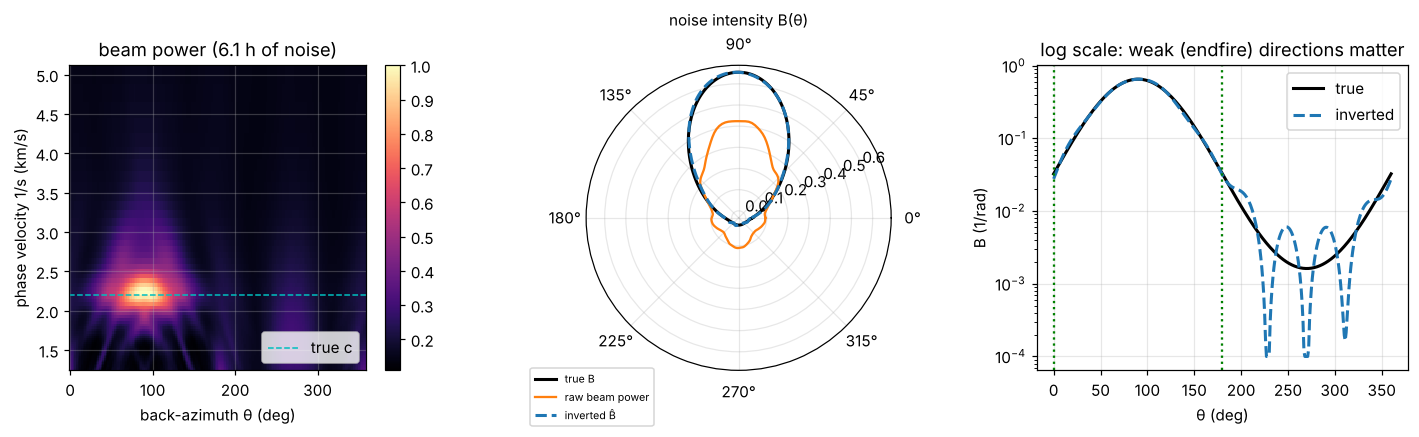

In [2]:
th0, k = np.pi / 2, 3.0
out = run(A, A, th0, k, n_windows=1000)
fig = plt.figure(figsize=(13, 4))
ax = fig.add_subplot(1, 3, 1)
im = ax.pcolormesh(np.degrees(out["th"]), 1 / out["sl"], out["P"] / out["P"].max(), shading="auto", cmap="magma")
ax.axhline(A.model.c0, color="c", ls="--", lw=1, label="true c")
ax.set(xlabel="back-azimuth θ (deg)", ylabel="phase velocity 1/s (km/s)",
       title=f"beam power ({1000 * WIN / 3600:.1f} h of noise)"); ax.legend(loc="lower right")
fig.colorbar(im, ax=ax)
ax = fig.add_subplot(1, 3, 2, projection="polar")
thp = np.linspace(0, 2 * np.pi, 361)
Praw = out["P"][out["ks"]]; Praw = Praw / np.trapezoid(np.r_[Praw, Praw[0]], np.r_[out["th"], 2 * np.pi])
ax.plot(thp, S.source_density(thp, th0, k), "k", lw=2, label="true B")
ax.plot(np.r_[out["th"], out["th"][:1]], np.r_[Praw, Praw[:1]], "C1", label="raw beam power")
ax.plot(thp, out["B_est"](thp), "C0--", lw=2, label="inverted B̂")
ax.set_title("noise intensity B(θ)", fontsize=10); ax.legend(fontsize=7, loc="lower left", bbox_to_anchor=(-0.2, -0.2))
ax = fig.add_subplot(1, 3, 3)
ax.semilogy(np.degrees(thp), S.source_density(thp, th0, k), "k", lw=2, label="true")
ax.semilogy(np.degrees(thp), np.clip(out["B_est"](thp), 1e-4, None), "C0--", lw=2, label="inverted")
[ax.axvline(a, color="g", ls=":") for a in (0, 180)]
ax.set(xlabel="θ (deg)", ylabel="B (1/rad)", title="log scale: weak (endfire) directions matter")
ax.legend(); plt.tight_layout()
print(f"beam phase velocity = {1 / out['sl'][out['ks']]:.3f} km/s (true {A.model.c0} km/s)")

The raw beam power is the true $B$ blurred by the array response and lifted by sidelobes, so it badly overestimates the weak directions. The inverted $\hat B$ removes most of that. For the bias, what matters is $B$ and its curvature in the **weak** directions: for east-west pairs, those are the endfire directions 0° and 180° (dotted lines). That is exactly where a noisy beam is least accurate.

## 2. How much bias is left after correction?

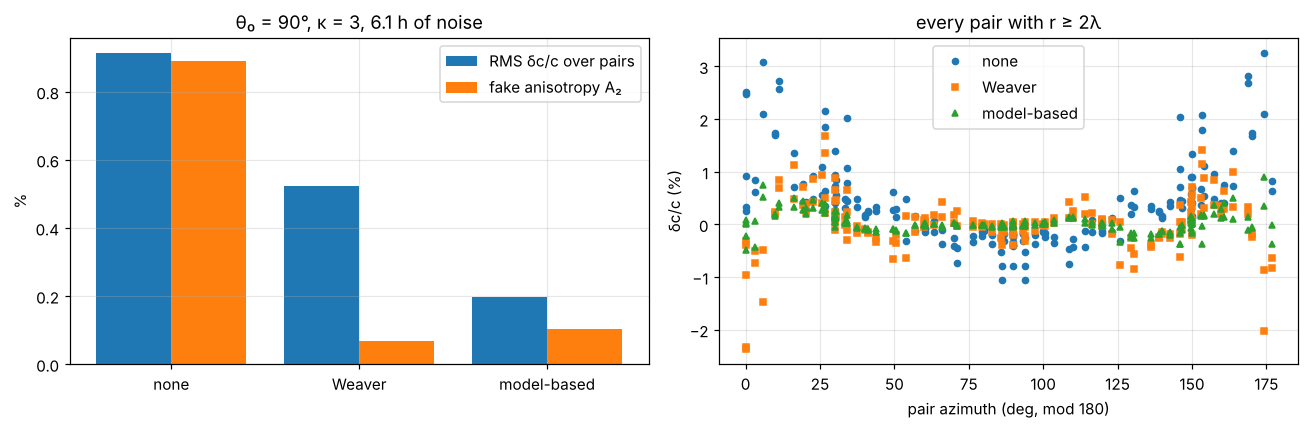

In [3]:
def bars(ax, score, title):
    names = list(score); x = np.arange(len(names))
    ax.bar(x - 0.2, [score[n][0] for n in names], 0.4, label="RMS δc/c over pairs")
    ax.bar(x + 0.2, [score[n][1] for n in names], 0.4, label="fake anisotropy A₂")
    ax.set_xticks(x, names); ax.set(ylabel="%", title=title)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bars(ax[0], out["score"], rf"θ₀ = 90°, κ = 3, {1000 * WIN / 3600:.1f} h of noise"); ax[0].legend()
for m, mk in [("none", "o"), ("Weaver", "s"), ("model-based", "^")]:
    ax[1].plot(np.degrees(out["az"]) % 180, -100 * out["res"][m] / out["t"], mk, ms=4, label=m)
ax[1].set(xlabel="pair azimuth (deg, mod 180)", ylabel="δc/c (%)", title="every pair with r ≥ 2λ")
ax[1].legend(); plt.tight_layout()

## 3. Concentration of the noise

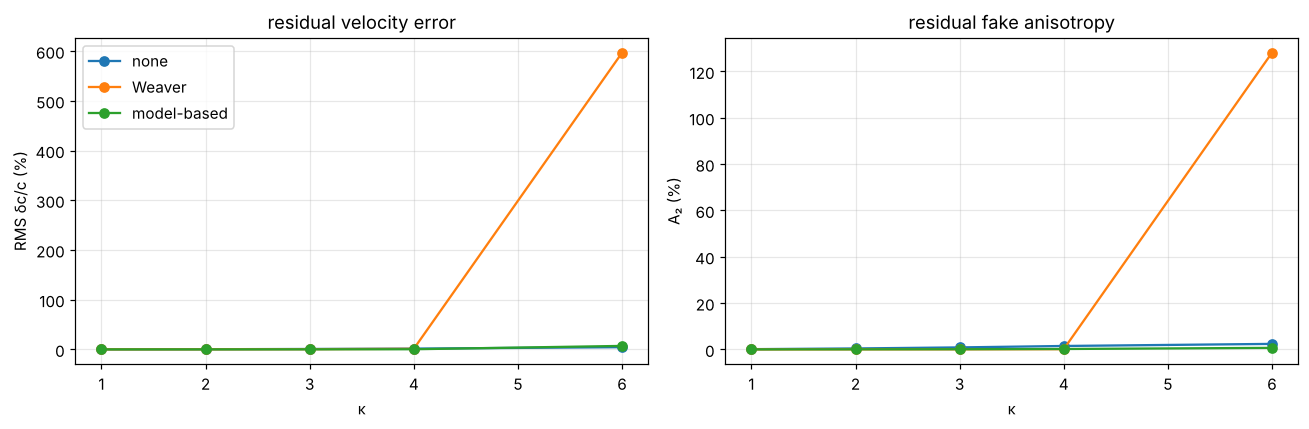

In [4]:
kappas = [1, 2, 3, 4, 6]
sc = {m: [] for m in ["none", "Weaver", "model-based"]}
for kk in kappas:
    s_ = run(A, A, th0, kk, n_windows=1000)["score"]
    [sc[m].append(s_[m]) for m in sc]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for m in sc:
    ax[0].plot(kappas, [v[0] for v in sc[m]], "o-", label=m)
    ax[1].plot(kappas, [v[1] for v in sc[m]], "o-", label=m)
ax[0].set(xlabel="κ", ylabel="RMS δc/c (%)", title="residual velocity error")
ax[1].set(xlabel="κ", ylabel="A₂ (%)", title="residual fake anisotropy"); ax[0].legend()
plt.tight_layout()

The Weaver correction works for moderate concentration but breaks down for strongly directional noise ($\kappa \gtrsim 5$). There, $B$ at endfire is nearly zero, so $B''/B$ blows up and the formula itself (stationary phase) is no longer valid. The model-based correction keeps working, because it does not linearise anything.

## 4. Recording length
A finite recording gives a noisy cross-spectral matrix. Its error falls as $1/\sqrt{N_\text{win}}$, and it hits the weak directions hardest. Three random realisations are run for each length.

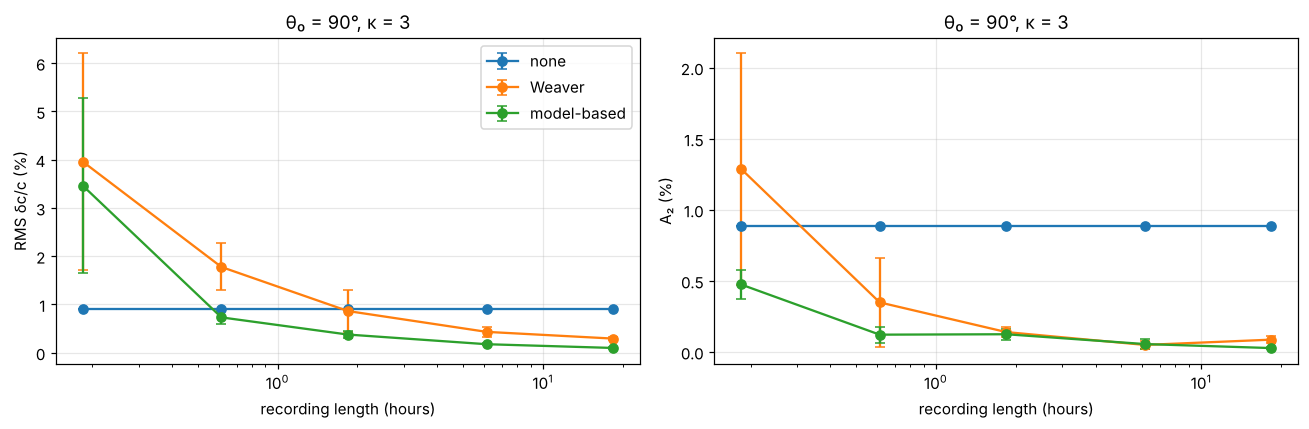

In [5]:
nwins = [30, 100, 300, 1000, 3000]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
scores = [[run(A, A, th0, 3.0, n_windows=n, seed=sd)["score"] for sd in range(3)] for n in nwins]
hours = np.array(nwins) * WIN / 3600
for m, col in [("none", "C0"), ("Weaver", "C1"), ("model-based", "C2")]:
    rms = np.array([[s_[m] for s_ in row] for row in scores])   # (n_len, seed, [rms, A2])
    for a, q in zip(ax, [0, 1]):
        a.errorbar(hours, rms[:, :, q].mean(1), rms[:, :, q].std(1), fmt="o-", color=col, capsize=3, label=m)
for a, lab in zip(ax, ["RMS δc/c (%)", "A₂ (%)"]):
    a.set(xscale="log", xlabel="recording length (hours)", ylabel=lab, title=f"θ₀ = 90°, κ = 3")
ax[0].legend(); plt.tight_layout()

With short recordings, correcting can do *worse* than not correcting. The noisy $\hat B$ puts spurious curvature into the weak endfire directions, and the Weaver formula amplifies it. The model-based correction pays off after about half an hour of noise and the Weaver correction after about 2 hours. Real deployments of days to weeks are well past that. These are idealised numbers: here the pair correlations themselves are noise-free. In real data they converge at the same $1/\sqrt{N}$ rate.

## 5. Size of the beamforming array
Beamforming uses only the stations inside a given radius (sub-array aperture $D$). The pairs being corrected are still all pairs of the full array. The recording is 1000 windows long.

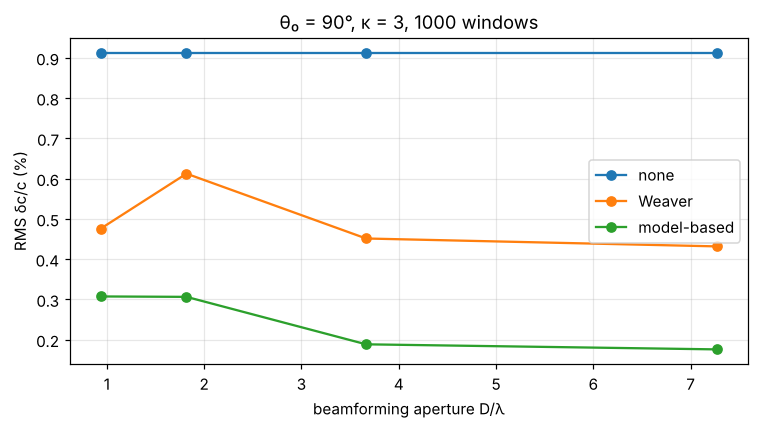

In [6]:
rad = np.hypot(*A.xy.T)
apert, scs = [], []
for rmax in [0.6, 1.1, 2.1, 4.1]:
    sub = A.subset(rad < rmax)
    apert.append(2 * rad[rad < rmax].max())
    runs = [run(A, sub, th0, 3.0, n_windows=1000, seed=sd)["score"] for sd in range(3)]
    scs.append(np.mean([[list(r_[m]) for m in ["none", "Weaver", "model-based"]] for r_ in runs], axis=0))
scs = np.array(scs)
fig, ax = plt.subplots(figsize=(7, 4))
for i, m in enumerate(["none", "Weaver", "model-based"]):
    ax.plot(np.array(apert) / (A.model.c0 / fc), scs[:, i, 0], "o-", label=m)
ax.set(xlabel="beamforming aperture D/λ", ylabel="RMS δc/c (%)", title="θ₀ = 90°, κ = 3, 1000 windows"); ax.legend()
plt.tight_layout()

## 6. Heterogeneous basin (model mismatch)
Both corrections assume a homogeneous medium. Here the true basin has 2% random velocity heterogeneity (100 m correlation length), and the stations and noise are the same as before. Each pair's bias is measured against the isotropic correlation in the same heterogeneous medium.

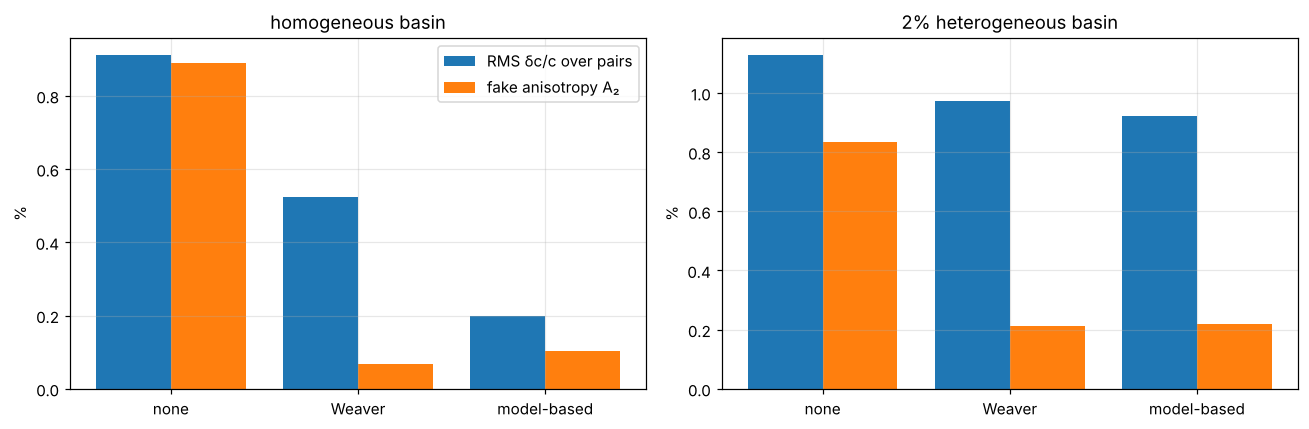

In [7]:
mh = S.Model(c=S.random_medium(S.Model(), rel_std=0.02, corr_len=0.1, seed=1))
Ah = S.ArrayExperiment(mh, S.hex_array())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bars(ax[0], run(A, A, th0, 3.0, n_windows=1000)["score"], "homogeneous basin")
bars(ax[1], run(Ah, Ah, th0, 3.0, n_windows=1000)["score"], "2% heterogeneous basin")
ax[0].legend(); plt.tight_layout()

## Summary
* A 2D array does make the bias **correctable**. Beamforming plus a damped Fourier-series inversion recovers $B(\theta)$ well. With enough data, both corrections remove most of the velocity error and of the fake anisotropy.
* **The Weaver correction** is simple, but it fails for strongly directional noise, where $B$ at endfire is near zero.
* **The model-based correction** works across the range tested, but it needs a model of the medium (here, the background velocity).
* **The limiting factor is data length more than array size.** The correction depends on $B$ in the weakest directions, so a short recording makes things worse. A larger beamforming aperture helps only modestly: the model-based residual goes from about 0.3% with a 1 km sub-array to 0.18% with 8 km, because the inversion accounts for the array response.
* **Heterogeneity** (scattering) introduces an error that a homogeneous-medium correction cannot remove: with 2% heterogeneity, both corrections still remove most of the fake anisotropy, but the RMS velocity error stays near 1%. This is the "moving target" in practice, along with time-varying sources.